In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [3]:
from src.conexao_banco import conn, cursor

- Primeira pergunta de negócio: Qual é a taxa de cancelamento por parte dos clientes e dos motoristas?

In [4]:
query = """
    WITH cancelleds AS (
        SELECT 
            COUNT(*) FILTER(WHERE "Booking_Status" = 'Cancelled by Driver') AS driver,
            COUNT(*) FILTER(WHERE "Booking_Status" = 'Cancelled by Customer') AS customer,
            COUNT(*) AS total
        FROM ncr_ride_bookings
        WHERE "Booking_Status" IN ('Cancelled by Driver', 'Cancelled by Customer')
    )

    SELECT
        ROUND(100 * driver / total::numeric, 2) AS tax_cancelled_driver,
        ROUND(100 * customer / total::numeric, 2) AS tax_cancelled_customer
    FROM cancelleds
"""

In [5]:
taxa_cancelamento_motorista_cliente = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_2748\577901269.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  taxa_cancelamento_motorista_cliente = pd.read_sql_query(query, conn)


In [6]:
taxa_cancelamento_motorista_cliente

,tax_cancelled_driver,tax_cancelled_customer
0,72.03,27.97


    Dentre o total dos cancelamentos, 72.03% dos cancelamentos ocorrem por parte dos motoristas e 27.97% ocorrem por parte dos clientes.

- Segunda pergunta de negócio: Quais são os principais motivos de cancelamento dos clientes?

In [7]:
query = """
    SELECT 
        "Reason_for_cancelling_by_Customer",
        ROUND(
            100 * COUNT(*) 
            / (
                SELECT 
                    COUNT(*) 
                FROM ncr_ride_bookings 
                WHERE "Booking_Status" = 'Cancelled by Customer'
            )::numeric, 2) as tax
    FROM ncr_ride_bookings
    WHERE "Booking_Status" = 'Cancelled by Customer'
    GROUP BY "Reason_for_cancelling_by_Customer"
    ORDER BY tax DESC
"""

In [8]:
motivos_cancelamentos_clientes = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_2748\1535771920.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  motivos_cancelamentos_clientes = pd.read_sql_query(query, conn)


In [9]:
motivos_cancelamentos_clientes

,Reason_for_cancelling_by_Customer,tax
0,Wrong Address,22.57
1,Change of plans,22.36
2,Driver is not moving towards pickup location,22.26
3,Driver asked to cancel,21.86
4,AC is not working,10.95


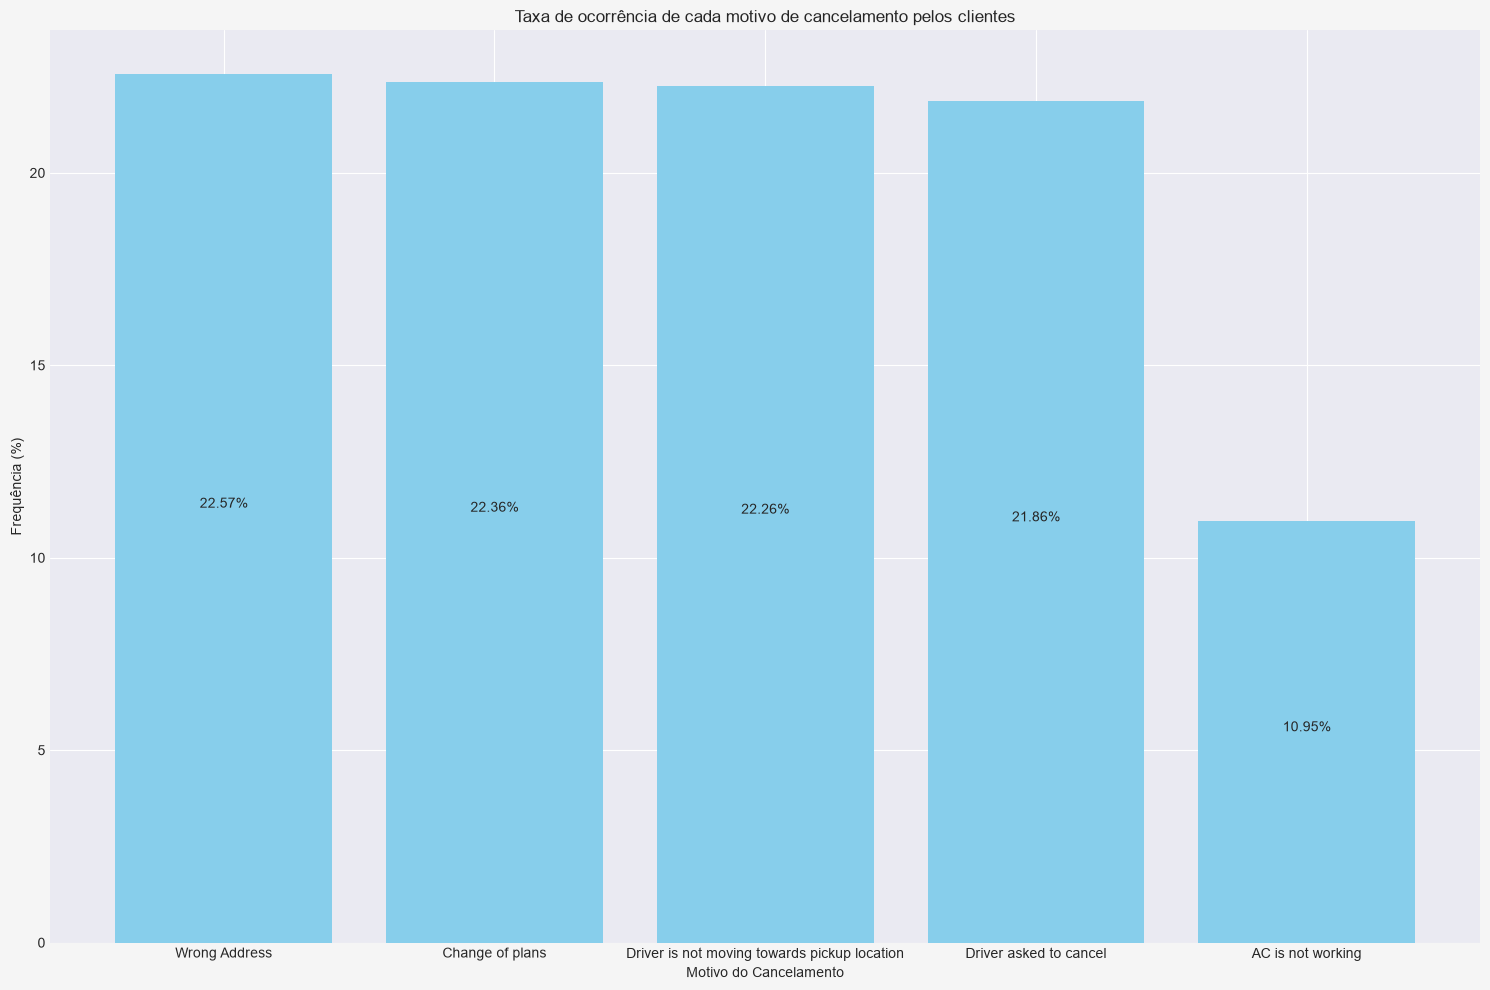

In [33]:
plt.figure(figsize=(15, 10))
plt.style.use('seaborn-v0_8-darkgrid')
plt.gcf().patch.set_facecolor('whitesmoke')

barras = plt.bar(motivos_cancelamentos_clientes['Reason_for_cancelling_by_Customer'], motivos_cancelamentos_clientes['tax'], color='skyblue')
plt.bar_label(barras, fmt='%.2f%%', padding=3, label_type='center')
plt.xlabel('Motivo do Cancelamento')
plt.ylabel('Frequência (%)')
plt.title('Taxa de ocorrência de cada motivo de cancelamento pelos clientes')
plt.tight_layout()
plt.show()

    Com exceção do motivo "Ar Condicionado não está funcionando", que apresentou a menor frequência entre os principais motivos de cancelamento, os demais motivos registraram taxas de ocorrência bastante semelhantes. Entre eles, destacam-se "Endereço errado", "Mudança de planos", "Motorista não está se movendo para o local de embarque" e "Motorista pediu para cancelar", que figuraram entre os motivos mais frequentes de cancelamento identificados na análise.

- Terceira pergunta de negócio: Quais são os principais motivos de cancelamento dos motoristas?

In [11]:
query = """
    SELECT 
        "Driver_Cancellation_Reason",
            ROUND(
                100 * COUNT(*) 
                / (
                    SELECT 
                        COUNT(*) 
                    FROM ncr_ride_bookings 
                    WHERE "Booking_Status" = 'Cancelled by Driver'
                )::numeric, 2) as tax
        FROM ncr_ride_bookings
        WHERE "Booking_Status" = 'Cancelled by Driver'
        GROUP BY "Driver_Cancellation_Reason"
        ORDER BY tax DESC
"""

In [12]:
motivos_cancelamentos_motoristas = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_2748\3030065.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  motivos_cancelamentos_motoristas = pd.read_sql_query(query, conn)


In [13]:
motivos_cancelamentos_motoristas

,Driver_Cancellation_Reason,tax
0,Customer related issue,25.30
1,The customer was coughing/sick,24.98
2,Personal & Car related issues,24.92
3,More than permitted people in there,24.80


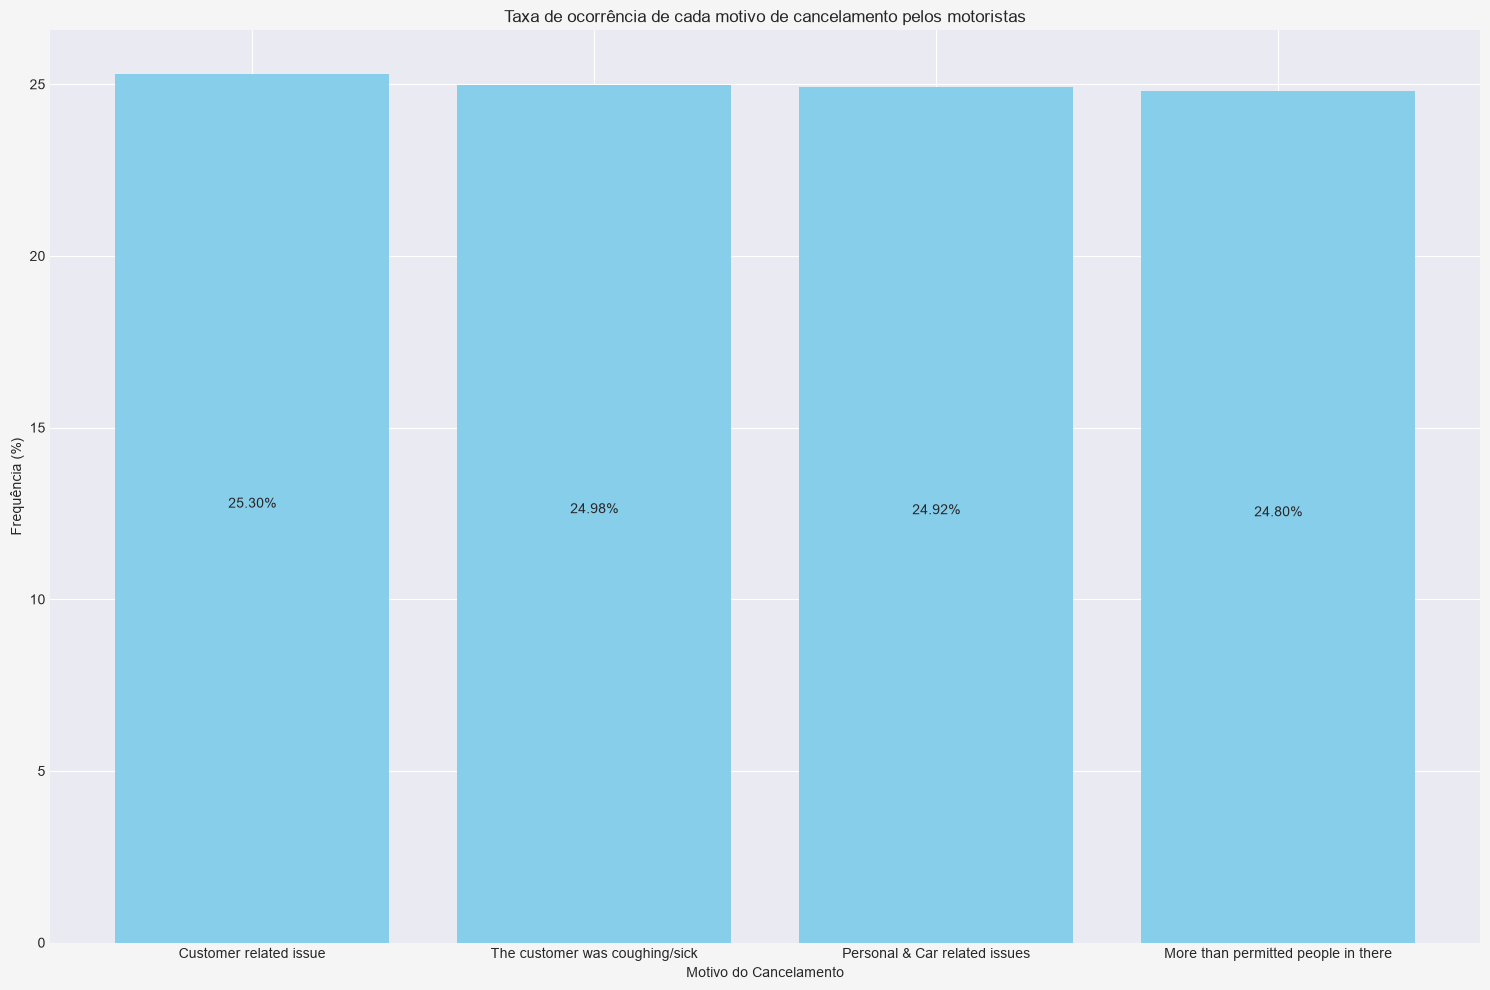

In [32]:
plt.figure(figsize=(15, 10))
plt.style.use('seaborn-v0_8-darkgrid')
plt.gcf().patch.set_facecolor('whitesmoke')

barras = plt.bar(motivos_cancelamentos_motoristas['Driver_Cancellation_Reason'], motivos_cancelamentos_motoristas['tax'], color='skyblue')
plt.bar_label(barras, fmt='%.2f%%', padding=3, label_type='center')
plt.xlabel('Motivo do Cancelamento')
plt.ylabel('Frequência (%)')
plt.title('Taxa de ocorrência de cada motivo de cancelamento pelos motoristas')
plt.tight_layout()
plt.show()

    Entre os motivos de cancelamento informados pelos motoristas, "Problema com o cliente", "Cliente está tossindo/doente", "Problemas pessoais ou com o carro" e "Número maior de pessoas permitidas no veículo" apresentaram frequências bastante semelhantes, representando aproximadamente 25% das ocorrências cada um.

- Quarta pergunta de negócio: Quais tipos de veículo apresentam maior incidência de cancelamentos?

In [15]:
query = """
    SELECT 
        "Vehicle_Type",
        COUNT(*) as incidence
    FROM ncr_ride_bookings
    WHERE "Booking_Status" IN ('Cancelled by Driver', 'Cancelled by Customer')
    GROUP BY "Vehicle_Type"
    ORDER BY "incidence" DESC
"""

In [16]:
veiculos_incidencia_cancelamentos = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_2748\2423283289.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  veiculos_incidencia_cancelamentos = pd.read_sql_query(query, conn)


In [17]:
veiculos_incidencia_cancelamentos

,Vehicle_Type,incidence
0,Auto,9249
1,Go Mini,7372
2,Go Sedan,6812
3,Bike,5593
4,Premier Sedan,4470
5,eBike,2610
6,Uber XL,1085


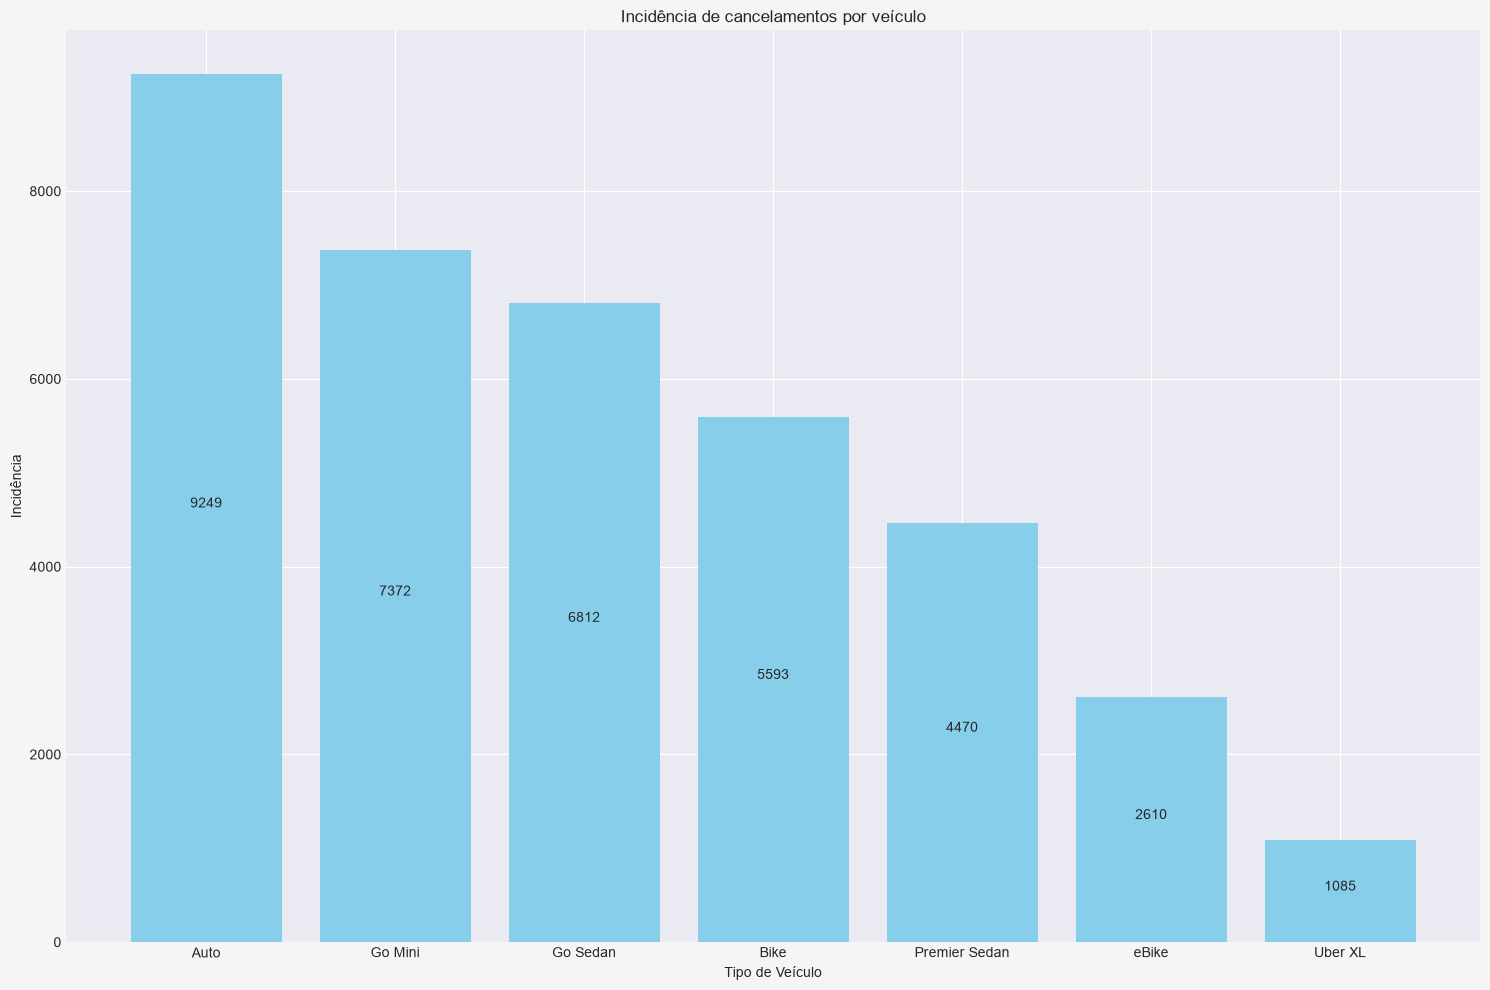

In [31]:
plt.figure(figsize=(15, 10))
plt.style.use('seaborn-v0_8-darkgrid')
plt.gcf().patch.set_facecolor('whitesmoke')

barras = plt.bar(veiculos_incidencia_cancelamentos['Vehicle_Type'], veiculos_incidencia_cancelamentos['incidence'], color='skyblue')
plt.bar_label(barras, padding=3, label_type='center')
plt.xlabel('Tipo de Veículo')
plt.ylabel('Incidência')
plt.title('Incidência de cancelamentos por veículo')
plt.tight_layout()
plt.show()

    O veículo Auto apresentou a maior incidência de cancelamentos, com 9.249 ocorrências, seguido pelo Go Mini, com 7.372, e pelo Go Sedan, com 6.812. Em contrapartida, o Uber XL registrou a menor incidência, com 1.085 ocorrências, seguido pelo eBike, com 2.610